# HW4: selected stock strategy and benchmark comparison

Sterling Couts

Required evaluation: April 1, 2016–September 30, 2026.


The selected strategy finishes at **$2,376,734.37**, versus
**$4,402,746.78** for the S&P 500 total-return benchmark. It trails by
**$2,026,012.40**, or **202.60
percentage points** of cumulative return. Its CAGR is **8.60%** versus
**15.17%**. Maximum drawdown is **-38.50%** versus
**-33.79%**, and Sharpe is **0.425** versus **0.773**.
The strategy does **not** beat the benchmark. Development gains did not
generalize to this required comparison; the risk and cost assumptions matter.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from hw4.settings import PROJECT
from hw4.data import checksum

assert Path(sys.executable).resolve() == (PROJECT / '.venv/Scripts/python.exe').resolve()
folder = PROJECT / 'results/fixed_anchor_final'
status = json.loads((folder / 'latest_status.json').read_text())
proof = json.loads((folder / 'verification.json').read_text())
assert status['verified'] and status['status'] == 'complete'
assert checksum(PROJECT / 'artifacts/fixed_anchor_2012.joblib') == proof['model_sha256']
nav = pd.read_csv(folder / 'daily_nav.csv', index_col='date', parse_dates=True)
metrics = pd.read_csv(folder / 'performance.csv', index_col=0)
assert nav.index[-1] == pd.Timestamp('2026-09-30')
assert np.isfinite(nav[['nav', 'benchmark_nav']]).all().all()
shown = metrics[['final_value', 'total_return', 'CAGR', 'max_drawdown', 'Sharpe']].copy()
shown['final_value'] = shown.final_value.map('${:,.2f}'.format)
for field in ['total_return', 'CAGR', 'max_drawdown']:
    shown[field] = shown[field].map('{:.2%}'.format)
shown['Sharpe'] = shown.Sharpe.map('{:.3f}'.format)
display(shown)

,final_value,total_return,CAGR,max_drawdown,Sharpe
strategy,"$2,376,734.37",137.67%,8.60%,-38.50%,0.425
benchmark,"$4,402,746.78",340.27%,15.17%,-33.79%,0.773


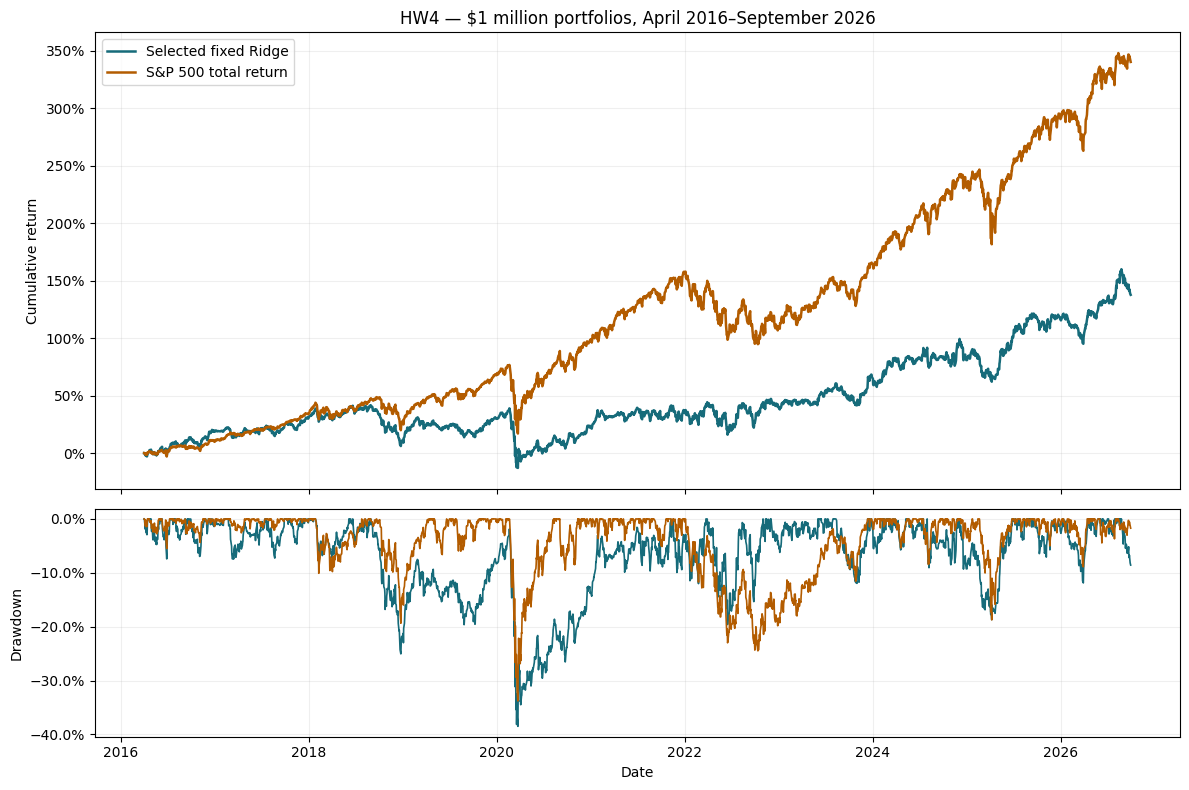

In [2]:
# The initial row is uninvested capital; include it to retain entry costs.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for field, label, color in [('nav', 'Selected fixed Ridge', '#166B7A'),
                            ('benchmark_nav', 'S&P 500 total return', '#B35C00')]:
    values = nav[field]
    axes[0].plot(values.index, values / 1e6 - 1, label=label, color=color, lw=1.8)
    axes[1].plot(values.index, values / values.cummax() - 1, color=color, lw=1.2)
axes[0].set(title='HW4 — $1 million portfolios, April 2016–September 2026',
            ylabel='Cumulative return')
axes[1].set(ylabel='Drawdown', xlabel='Date')
axes[0].legend(loc='upper left')
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(folder / 'comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## Features, model and chronology

The model predicts the simple adjusted-price return from the **next session's
close** to the first market close on or after **90 calendar days** from entry.
Each monthly signal uses only information available by that signal close.
Quarterly historical membership determines the entry universe, including inactive
stocks; leaving the universe does not cause an early sale.

Eight inputs are percentile ranks within the eligible cross-section on the same
date: 21- and 63-session momentum; 252-to-21 and 126-to-21 momentum; 63-session
annualized volatility; drawdown from the trailing 252-session high; quarterly
operating income/assets; and quarterly free cash flow/assets. Ranks reduce the
influence of incomparable numerical scales, but discard magnitude information.

The selected estimator is **Ridge, alpha 1000**, with training-only median
imputation, missing indicators and standardization. The training response is
winsorized at its training 1st/99th percentiles; actual portfolio returns and
prices are never winsorized. This estimates a robust response, not an unrestricted
conditional expected return. Penalties and feature choices were compared during
development. Complexity did not reliably improve performance.

The retained fit is dated **December 31, 2012**, using **51,633** observations:
signals from January 29, 2010 through August 31, 2012, with the last included
outcome complete on December 3, 2012. The 2013–2015 period supports development
comparisons. Earlier prices supply lookbacks. The assignment's January–March
2016 buffer is not used to refit this selected estimator. Coefficients and learned
preprocessing stay fixed; features and predictions refresh monthly. Retraining
is optional under HW4.

Financials are available on **filing date + 1 calendar day**. Missing filing dates
and filing dates on/before fiscal period end are excluded, rather than repaired
with guessed knowledge dates. Statements more than 550 days old are missing.
No future backfill is used. The source's restated snapshot is not a complete
point-in-time archive of original filings.

## Trading and accounting

Start with $1 million, long only, no borrowing. At each monthly signal, rank
eligible candidates and allocate available cash to at most 20 names, subject to
**5% recorded-symbol and 20% supplied-sector entry limits**. Decisions use
prior-close cash and exposure; execution is at the next session's close, with
**5 basis points per side**. Entry limits constrain planned purchases; subsequent
price movements can take weights above those limits. The model does not trim
winners early. Each lot is sold at its own 90-day maturity or next session if the
market is closed. Maturity proceeds wait for the next monthly purchase date.
Cash earns zero interest. Fractional adjusted-price units are permitted.

Candidates require observable prices and complete recent return history. The
declared risk screen uses trailing volatility at most 80%, 252 positive-volume
sessions, and no trailing daily price ratio outside [0.5, 2]. These are causal
entry restrictions, not declarations that excluded observations are errors.
Unknown future exit prices never remove a prediction candidate.

Use supplied adjusted prices consistently, without adding dividends again.
Missing marks may carry forward for at most five sessions; missing execution
prices never become fabricated fills. Verified mandatory mergers or ticker
changes are booked separately from discretionary trades. Replacement exposures
retain original maturity; cash consideration becomes a receivable, spendable
after two market sessions (a simulation convention, not a claimed broker date).
The source database is read-only. Cited repairs and limited successor quotes are
separate inputs under `research_events/`.

## Interpretation and limitations

The reported comparison uses fixed model coefficients and trading rules.
Development winners may reflect selection noise.
Static vendor sectors, incomplete historical issuer mappings, restated financial
vintages and imperfect adjusted prices limit the economic interpretation. The
5% cap is per recorded ticker, not a certified issuer-wide cap. Execution assumes
closing fills and proportional costs without market impact, taxes or financing.
Accounting reconciliation validates the calculation; it does not certify every
vendor observation or establish future profitability.

## Key development comparisons (2013–2015)

All rows below use continuous accounts, not products of annual reset tests.
The table is a selected research summary; its rows span different model and
allocation stages. Read the change and evidence columns before attributing an
improvement to one cause. The matching benchmark returned 48.78%.

In [3]:
development = pd.read_csv(folder / 'selected_development_comparisons.csv')
shown = development[['experiment', 'change', 'total_return', 'max_drawdown', 'Sharpe']].copy()
for field in ['total_return', 'max_drawdown']:
    shown[field] = shown[field].map('{:.2%}'.format)
shown['Sharpe'] = shown.Sharpe.map('{:.3f}'.format)
display(shown)

,experiment,change,total_return,max_drawdown,Sharpe
0,One momentum input,Original simple linear baseline,35.96%,-30.14%,0.512
1,Price ranks,"Multiple price/risk ranks, quarterly updates",44.37%,-23.00%,0.670
2,+ profitability,Add operating ROA and cash-flow/assets to pric...,53.27%,-16.84%,0.887
3,Fixed eight-rank Ridge,Include six-month momentum; fixed pre-2013 fit,62.85%,-15.78%,1.063
4,Full available cash,Increase monthly deployment budget; no sector cap,79.04%,-18.27%,1.116
5,+ 20% sector limit,Keep 5% stock cap; limit sector entry exposure,83.68%,-14.98%,1.277
6,Fresh reinvestment signals,Extra next-session entries with newly computed...,87.96%,-17.61%,1.210
7,Annual replacement,Same monthly allocation; replace the fitted mo...,63.08%,-16.58%,0.991
8,50/50 forecast average,Same monthly allocation; average original and ...,83.30%,-15.52%,1.270
9,Selected fixed monthly model,Retain original fit and 5%/20% monthly allocation,83.68%,-14.98%,1.277


**Selection reasoning.** Rank features and profitability improved the early
price-only comparison. Full cash deployment and a sector entry limit helped
development performance. Fresh next-session reinvestment returned 87.96%,
compared with 83.68% monthly, but deepened drawdown from 14.98% to 17.61%.
Sterling selected monthly purchases for simplicity and lower development
drawdown. Annual replacement returned 63.08%; averaging old and new forecasts
returned 83.30%, so the original fixed fit was retained.

Additional financial-change and price-path signals did not establish stable
improvements across chronological checks. Longer filing delays sometimes
improved a continuous account but were not robust to fitting and allocation
changes. They were not adopted. These findings support restraint, not a claim
that there is no possible signal in those variables.

## Accounting and data-quality evidence


Independent checks reconcile **2,641 daily NAV rows**,
**4,617 fills**, **8 corporate-action
lot transitions**, and **32 terminal open lots**.
Maximum NAV reconstruction difference is less than $0.000001. Timing,
dated membership, cash, costs, lot maturity, entry limits and daily metrics
pass. The full suite has **170 passing tests**.

The price review screens **117** held daily moves over
20%: **92** have independent provider observations,
all within 0.5 percentage point of the supplied adjusted return;
**25** remain unverified because the endpoint did
not supply usable observations. Genuine large returns are retained.
This is a measured verification scope, not blanket data certification.

In [4]:
# Independent identity check in addition to the separately rebuilt ledger.
np.testing.assert_allclose(nav.nav, nav.cash + nav.holdings + nav.receivables, atol=1e-6, rtol=0)
assert nav.cash.min() >= -1e-6  # Floating-point tolerance, not borrowing.
local = PROJECT / status['local_output']
fills = pd.read_csv(local / 'fills.csv')
events = pd.read_csv(local / 'events.csv')
display(pd.Series({
    'Final cash': nav.cash.iloc[-1],
    'Final holdings': nav.holdings.iloc[-1],
    'Final receivables': nav.receivables.iloc[-1],
    'Total trading fees': fills.fee.sum(),
    'Mean daily cash fraction': (nav.cash / nav.nav).iloc[1:].mean(),
    'Maximum observed symbol weight': proof['maximum_recorded_name_weight'],
    'Maximum observed sector weight': proof['maximum_sector_weight'],
}, name='Account diagnostics').to_frame())
display(events[['date', 'event_id', 'old_symbol', 'new_symbol', 'original_maturity']])
print('Account identity and saved-model checks passed.')

,Account diagnostics
Final cash,1.774062e+06
Final holdings,6.026721e+05
Final receivables,0.000000e+00
Total trading fees,4.852999e+04
Mean daily cash fraction,2.148720e-01
Maximum observed symbol weight,9.247888e-02
Maximum observed sector weight,2.540736e-01


,date,event_id,old_symbol,new_symbol,original_maturity
0,2017-04-06,TASR_20170406,TASR,AXON,2017-05-02
1,2017-04-06,TASR_20170406,TASR,AXON,2017-05-30
2,2022-09-02,CDEV_20220902,CDEV,PR,2022-11-30
3,2023-01-09,LPI_20230109,LPI,VTLE,2023-03-01
4,2024-08-22,GPS_20240822,GPS,GAP,2024-09-01
5,2025-06-09,CSWI_20250609,CSWI,CSW,2025-08-31
6,2026-02-24,ATGE_20260224,ATGE,CVSA,2026-04-02
7,2026-05-18,SLNO_20260518,SLNO,NaN,2026-05-31


Account identity and saved-model checks passed.


**Data treatment.** Cited merger/rename terms carry holdings through actual
events. Known COKE/TPL/BKNG/REZI/SPKE/CVNA unit discontinuities are normalized
consistently in features and valuation. Changes preserve within-segment
returns; a split is not credited a second time. CVSA observations cover only
the inherited ATGE lot through its original April 2, 2026 maturity. Source
citations and observed-price evidence are in `research_events/`; raw course
data remains unchanged. No disappeared security receives an invented sale.

# Learning guide: explaining the selected strategy

**Research question.** Can a simple relationship between relative price behavior,
risk and profitability rank stocks usefully over a 90-day holding period?
Separate three objects: the predictor produces scores, the portfolio rule turns
scores into orders, and the ledger records the economic result.

1. **A dated row is an information set.** A fiscal quarter ending in March is
   not known in March if the company files in May. Use filing+1, and ensure the
   next-session entry follows the signal. Training also needs completed labels.
2. **A rank is relative.** A momentum percentile of 0.9 means approximately the
   top tenth of peers on that date, not a forecast of 90% return. It can change
   when peer values change even if that stock's own momentum stays constant.
3. **Ridge regularizes correlated predictors.** It penalizes squared coefficient
   size. Standardization makes the penalty comparable across inputs; alpha1000
   was a development choice. More features or a nonlinear model need evidence,
   not an assumption that complexity must help.
4. **Fit and predict are different operations.** Fit learns medians, scales,
   coefficients and target bounds. Predict applies those saved quantities to new
   observations. This project refreshes inputs monthly without refitting.
5. **Target and trade must agree.** For signal t, entry e is the next session;
   maturity m is e+90 calendar days, moved to the next market session. The target
   is P(m)/P(e)-1, not a return beginning at t. Overlapping lots remain separate.
6. **A ledger is a conservation check.** NAV = cash + marked holdings + cash
   receivables. Buys reduce cash by notional plus cost; sells add notional minus
   cost. Corporate conversions require unit consistency and cannot create wealth
   just because a ticker or price scale changes.
7. **Performance is not prediction accuracy.** Rankings, idle cash, concentration,
   costs and the holding rule determine realized returns. Annual fresh-cash tests
   are diagnostics and must not be compounded into a continuous portfolio result.
8. **A test proves its stated condition.** Hand cases check arithmetic and timing;
   an independent ledger checks the full account; source comparisons check some
   data. None proves that every source row is true or that future returns follow
   the backtest. Keep unresolved evidence visible and avoid tuning on the final
   comparison.

Metric conventions: daily simple return r(t)=NAV(t)/NAV(t-1)-1; CAGR uses elapsed
calendar years from first evaluation close to final close; drawdown is
NAV(t)/running_max(NAV)-1. Sharpe = sqrt(252) × (mean(r)-rf_daily)/sample_sd(r),
where rf_daily=(1.02)^(1/252)-1. An initial pre-trade row includes entry costs in
strategy performance; benchmark purchase at the first test close has no initial
market return.

To review independently, explain why a missing future label is retained at
prediction time, trace one buy to its maturity, and reconcile a day's cash and
holdings. Then explain why the 5%/20% entry rules permit later weight drift.
These are the most useful interview exercises for this implementation.

Next research would need new chronological evidence: rolling stability of the
rank coefficients, broader issuer-aware data quality checks, and execution/cost
stress. Do not select another strategy from this reported final comparison.

## Attribution and reproducibility

Data: course `equities_top2000.duckdb`, with historical membership and ^SP500TR.
Course references: `Lectures/modeling/README.md`, Lecture 7 feature engineering
and transformer examples, and Lecture 8 research-workflow examples and
`hw4.md`. Data-loading, financial availability, pipeline and chronological
validation ideas adapt those materials; adaptation notes accompany the code.
The portfolio planner and lot/event ledger are implemented in this project,
rather than delegated to a backtesting library. External corporate-action
sources and limited quote supplements are cited in their saved registries.

**AI assistance:** Codex assisted with implementation, debugging, tests,
data-source investigation and documentation. Sterling directed hypotheses
and comparisons, discussed concepts and selected the final model and trading
policy. The submission should be explained from the code and evidence above.

`README.md` gives setup and run commands. `PROGRESS.md` maps requirements to
evidence. This notebook reads verified saved results and runs independently
in the project kernel; it does not select or retrain a model.